# Modelado experimental 

In [381]:
import os
import sys

# Agrega el directorio padre (raíz del proyecto) al path de Python
sys.path.append(os.path.abspath(os.path.join('..')))

In [382]:
# ============================================================
# 1. MANIPULACIÓN Y ANÁLISIS DE DATOS
# ============================================================

import numpy as np
import pandas as pd

In [383]:
# ============================================================
# 2. VISUALIZACIÓN DE DATOS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Image

In [ ]:
# ============================================================
# 3. PREPROCESAMIENTO Y REDUCCIÓN DE DIMENSIONALIDAD
# ============================================================

from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import KernelPCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import trustworthiness

from sklearn.feature_selection import SelectKBest, f_classif, chi2
from scipy.stats import chi2_contingency

In [385]:
# ============================================================
# 4. MODELOS DE MACHINE LEARNING
# ============================================================

from sklearn.linear_model import LogisticRegression, SGDClassifier

from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    VotingClassifier,
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
    export_text,
    export_graphviz,
    _tree
)

from xgboost import XGBClassifier

In [386]:
# ============================================================
# 5. SELECCIÓN, VALIDACIÓN Y AJUSTE DE MODELOS
# ============================================================

from sklearn.base import clone

from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)

from sklearn.pipeline import Pipeline

In [387]:
# ============================================================
# 6. MÉTRICAS DE EVALUACIÓN
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_recall_curve,
    precision_score,
    PrecisionRecallDisplay,
    r2_score,
    recall_score,
    roc_auc_score,
)
from src.eval_models import eval_model

In [388]:
# ============================================================
# 7. VISUALIZACIÓN DE ÁRBOLES DE DECISIÓN
# ============================================================

import graphviz

In [389]:
# ============================================================
# 8. SISTEMA, UTILIDADES Y SERIALIZACIÓN
# ============================================================

import sys
import os
import pprint
import joblib

In [390]:
# ============================================================
# 9. FUNCIONES Y TRANSFORMACIONES PROPIAS
# ============================================================

from src.custom_standarization_classes_and_functions import GeneralPreprocessor

### Importacion de datos

In [391]:
path_df_processed = '../data/3_gold/df_processed.csv'
df_processed = pd.read_csv(path_df_processed)
df_processed.sample(5)

,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
1619,57,Male,Handbag,Accessories,78,Hawaii,L,Beige,Winter,3.5,No,Store Pickup,Yes,50,Venmo,Bi-Weekly
465,54,Male,Skirt,Clothing,88,Oklahoma,M,Pink,Summer,2.8,Yes,Next Day Air,Yes,25,Cash,Quarterly
1199,49,Male,Sandals,Footwear,89,Maryland,M,Indigo,Fall,4.5,No,Free Shipping,Yes,3,Debit Card,Weekly
1116,67,Male,Backpack,Accessories,96,Hawaii,M,Charcoal,Winter,4.2,No,Express,Yes,39,PayPal,Fortnightly
3622,46,Female,Dress,Clothing,41,Wisconsin,M,Purple,Fall,4.3,No,Store Pickup,No,12,Credit Card,Annually


### Separacion de datos

In [392]:
top_columns = joblib.load('../artifacts/top_columns.joblib')

In [393]:
top_columns

['purchase_amount_usd',
 'review_rating',
 'previous_purchases',
 'promo_code_used',
 'gender',
 'location',
 'shipping_type',
 'payment_method',
 'frequency_of_purchases']

In [394]:
g_preprocessor = GeneralPreprocessor()

In [396]:
df_processed = g_preprocessor.fit_transform(X=df_processed)
df_processed = pd.DataFrame(data=df_processed, columns=g_preprocessor.get_feature_names_out())
df_processed

,age,gender,item_purchased,category_item,purchase_amount_usd,location,size,color,season,review_rating,subscription_status,shipping_type,promo_code_used,previous_purchases,payment_method,frequency_of_purchases
0,55,male,blouse,clothing,53,kentucky,l,gray,winter,3.1,yes,express,yes,14,venmo,bi-weekly
1,19,male,sweater,clothing,64,maine,l,maroon,winter,3.1,yes,express,yes,2,cash,bi-weekly
2,50,male,jeans,clothing,73,massachusetts,s,maroon,spring,3.1,yes,free shipping,yes,23,credit card,weekly
3,21,male,sandals,footwear,90,rhode island,m,maroon,spring,3.5,yes,next day air,yes,49,paypal,weekly
4,45,male,blouse,clothing,49,oregon,m,turquoise,spring,2.7,yes,free shipping,yes,31,paypal,annually
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,40,female,hoodie,clothing,28,virginia,l,turquoise,summer,4.2,no,2-day shipping,no,32,venmo,weekly
3896,52,female,backpack,accessories,49,iowa,l,white,spring,4.5,no,store pickup,no,41,bank transfer,bi-weekly
3897,46,female,belt,accessories,33,new jersey,l,green,spring,2.9,no,standard,no,24,venmo,quarterly
3898,44,female,shoes,footwear,77,minnesota,s,brown,summer,3.8,no,express,no,24,venmo,weekly


In [397]:
# separo las las variables de la variable target
X = df_processed[top_columns].copy()
y = df_processed['subscription_status'].copy()

In [398]:
y = y.map({'No':0, 'Yes':1})

In [399]:
# Divido las variable target y el resto de variables en testeo y prueba utilizando un 35% de datos para prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

### Instancia y creación de grilla de hiperparámeotros por medio de GridSearchCV

No se observo relaciones o tendencias lineales de manera bivariada. Pero antes de descartar una posible relacion lineal mas alla de combinaciones bivaraiadas, y dada la muestra relativamente chica. Dado el ruido y en general baja seńal observada en el analisis bivariado contra larget, provaremos multiples combinaciones de reducciones lineales y no lineales, al igual que modelos de clasificación robustos y con cierta regularización o robustes ante la varianza en las predicciones.

In [334]:
reduction_options = {
    "Sin reducción": "passthrough",

    "LDA": LinearDiscriminantAnalysis()#,

    #"UMAP": UMAP(
    #   random_state=42
    #)
}

ElasticNet

In [335]:
elasticnet = SGDClassifier(
    loss="log_loss",
    penalty="elasticnet",
    max_iter=3000,
    random_state=42
)

grid_elasticnet = {
    "model__alpha": [0.0001, 0.001, 0.01],
    "model__l1_ratio": [0.2, 0.5, 0.8]
}

SVMLineal

In [336]:
svm_linear = SVC(
    kernel="linear",
    probability=True,
    random_state=42
)

grid_svm_linear = {
    "model__C": [0.1, 1, 10, 100]
}

SVM con kernel RBF

In [337]:
svm_rbf = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

grid_svm_rbf = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}

KNN

In [338]:
knn = KNeighborsClassifier()

grid_knn = {
    "model__n_neighbors": [3, 5, 7, 11, 15],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

Arbol individual (con inyección de coste hipotetico de 0.4 para no subscritos y 0.6 para predecir subscriptos.)

In [339]:
decision_tree = DecisionTreeClassifier(
    random_state=42,
    class_weight={0:0.4, 1:0.6}
)

grid_decision_tree = {
    # Control de profundidad
    "model__max_depth": [3, 5, 7, 9],
    # Fracción mínima de muestras para dividir un nodo
    "model__min_samples_split": [0.007, 0.01, 0.02, 0.05, 0.10],
    # Fracción mínima de muestras por hoja
    "model__min_samples_leaf": [0.01, 0.02, 0.05, 0.10],
    # Poda del árbol
    "model__ccp_alpha": [0.0, 0.001, 0.01],
    # Reducción mínima de impureza para dividir
    "model__min_impurity_decrease": [0.0005, 0.001, 0.005, 0.01, 0.015],
    # Criterios de división
    "model__criterion": ["gini", "entropy", "log_loss"]
}

Random Forest

In [340]:
random_forest = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

grid_random_forest = {
    "model__n_estimators": [200, 500],
    "model__max_depth": [None, 10, 7],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.5]
}

XGBoost

In [341]:
xgboost = XGBClassifier(
    random_state=42,
    eval_metric="logloss",
    n_jobs=1
)

grid_xgboost = {
    "model__n_estimators": [200, 500],
    "model__max_depth": [3, 6, 10],
    "model__learning_rate": [0.03, 0.1],
    "model__subsample": [0.8, 1.0]
}

MLPClassifier

In [342]:
mlp = MLPClassifier(
    max_iter=500,
    early_stopping=True,
    random_state=42
)

grid_mlp = {
    "model__hidden_layer_sizes": [
        (50,),
        (100,),
        (100, 50)
    ],
    "model__activation": ["relu", "tanh"],
    "model__alpha": [0.0001, 0.001, 0.01],
    "model__learning_rate_init": [0.001, 0.01]
}

In [343]:
preprocessor = joblib.load('../artifacts/preprocessor.joblib')

In [344]:
pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("reduction", "passthrough"),
    ("model", clone(elasticnet))
])

21 combinaciones / experimentos: Modelos x Hiperparametros x Valores de hiperparametros

In [345]:
models = [
    ("ElasticNet", elasticnet, grid_elasticnet),
    ("SVM lineal", svm_linear, grid_svm_linear),
    ("SVM RBF", svm_rbf, grid_svm_rbf),
    ("KNN", knn, grid_knn),
    ("DecisionTreeClassifier", decision_tree, grid_decision_tree),
    ("Random Forest", random_forest, grid_random_forest),
    ("XGBoost", xgboost, grid_xgboost),
    ("MLPClassifier", mlp, grid_mlp)
]

In [346]:
experiments = []

for model_name, model, model_grid in models:

    for reduction_name, reduction in reduction_options.items():

        params = dict(model_grid)

        params["model"] = [clone(model)]

        if reduction_name == "Sin reducción":
            params["reduction"] = ["passthrough"]

        elif reduction_name == "LDA":
            params["reduction"] = [
                LinearDiscriminantAnalysis()
            ]

        elif reduction_name == "UMAP":
            params["reduction"] = [
                UMAP(random_state=42)
            ]

            params["reduction__n_components"] = [5, 10, 20]
            params["reduction__n_neighbors"] = [10, 15, 30]
            params["reduction__min_dist"] = [0.0, 0.1, 0.5]

        experiments.append({
            "nombre_modelo": model_name,
            "reduccion": reduction_name,
            "param_grid": params
        })

### Entrenamiento y optimización con GridSearchCV

In [347]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [348]:
results = []
best_models = {}
search_objects = {}

for experiment in experiments:

    model_name = experiment["nombre_modelo"]
    reduction_name = experiment["reduccion"]
    params = experiment["param_grid"]
    print(
        f"\nEntrenando {model_name} "
        f"| Reducción: {reduction_name}"
    )

    search = GridSearchCV(
        estimator=clone(pipeline),
        param_grid=params,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        error_score="raise",
        return_train_score=True,
        verbose=0
    )

    search.fit(X, y)

    results.append({
        "Modelo": model_name,
        "Reducción": reduction_name,
        "Mejor AUC CV": search.best_score_,
        "Mejores parámetros": search.best_params_,
        "Desviación AUC CV": search.cv_results_["std_test_score"][
            search.best_index_
        ],
        "AUC entrenamiento": search.cv_results_["mean_train_score"][
            search.best_index_
        ]
    })

    best_models[(model_name, reduction_name)] = search.best_estimator_
    search_objects[(model_name, reduction_name)] = search
    print(f"Mejor AUC CV: {search.best_score_:.4f}")
    print(f"Mejores parámetros: {search.best_params_}")

print("\nExperimentos finalizados.")


Entrenando ElasticNet | Reducción: Sin reducción
Mejor AUC CV: 0.8944
Mejores parámetros: {'model': SGDClassifier(loss='log_loss', max_iter=3000, penalty='elasticnet',
              random_state=42), 'model__alpha': 0.0001, 'model__l1_ratio': 0.2, 'reduction': 'passthrough'}

Entrenando ElasticNet | Reducción: LDA
Mejor AUC CV: 0.8872
Mejores parámetros: {'model': SGDClassifier(loss='log_loss', max_iter=3000, penalty='elasticnet',
              random_state=42), 'model__alpha': 0.0001, 'model__l1_ratio': 0.2, 'reduction': LinearDiscriminantAnalysis()}

Entrenando SVM lineal | Reducción: Sin reducción
Mejor AUC CV: 0.8914
Mejores parámetros: {'model': SVC(kernel='linear', probability=True, random_state=42), 'model__C': 100, 'reduction': 'passthrough'}

Entrenando SVM lineal | Reducción: LDA
Mejor AUC CV: 0.8872
Mejores parámetros: {'model': SVC(kernel='linear', probability=True, random_state=42), 'model__C': 0.1, 'reduction': LinearDiscriminantAnalysis()}

Entrenando SVM RBF | Reducció

In [349]:
df_results = pd.DataFrame(results)

In [350]:
df_results = df_results.sort_values(
    by="Mejor AUC CV",
    ascending=False
).reset_index(drop=True)

df_results

,Modelo,Reducción,Mejor AUC CV,Mejores parámetros,Desviación AUC CV,AUC entrenamiento
0,XGBoost,Sin reducción,0.898783,"{'model': XGBClassifier(base_score=None, boost...",0.007866,0.927643
1,Random Forest,Sin reducción,0.896153,"{'model': RandomForestClassifier(n_jobs=1, ran...",0.006359,0.964412
2,SVM RBF,Sin reducción,0.896148,"{'model': SVC(probability=True, random_state=4...",0.008068,0.902603
3,MLPClassifier,Sin reducción,0.895414,"{'model': MLPClassifier(early_stopping=True, m...",0.014084,0.894089
4,ElasticNet,Sin reducción,0.894443,"{'model': SGDClassifier(loss='log_loss', max_i...",0.015010,0.889957
5,DecisionTreeClassifier,Sin reducción,0.893854,{'model': DecisionTreeClassifier(class_weight=...,0.011785,0.907090
6,SVM RBF,LDA,0.893260,"{'model': SVC(probability=True, random_state=4...",0.009472,0.890390
7,Random Forest,LDA,0.891684,"{'model': RandomForestClassifier(n_jobs=1, ran...",0.010736,0.989237
8,SVM lineal,Sin reducción,0.891360,"{'model': SVC(kernel='linear', probability=Tru...",0.007678,0.892476
9,DecisionTreeClassifier,LDA,0.890107,{'model': DecisionTreeClassifier(class_weight=...,0.008820,0.890586


#### Arbol de desición simple

In [351]:
best_models[('DecisionTreeClassifier', 'Sin reducción')]

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('all_columns', GeneralPreprocessor()),
                                 ('by_data_type_columns',
                                  ColumnTransformer(sparse_threshold=0,
                                                    transformers=[('numeric',
                                                                   'passthrough',
                                                                   ['purchase_amount_usd',
                                                                    'review_rating',
                                                                    'previous_purchases']),
                                                                  ('ordinal',
                                                                   Pipeline(steps=[('encoder',
                                                                                    OrdinalEncoder(categories=[['no',
                                                                                                                'yes'],
                                                                                                               ['annually',
                                                                                                                'quarterly',...
                                                                                                                'bi-weekly',
                                                                                                                'weekly']],
                                                                                                   handle_unknown='use_encoded_value',
                                                                                                   unknown_value=-1))]),
                                                                   ['promo_code_used',
                                                                    'frequency_of_purchases'])]))])),
                ('reduction', 'passthrough'),
                ('model',
                 DecisionTreeClassifier(ccp_alpha=0.001,
                                        class_weight={0: 0.4, 1: 0.6},
                                        criterion='entropy', max_depth=5,
                                        min_impurity_decrease=0.0005,
                                        min_samples_leaf=0.02,
                                        min_samples_split=0.007,
                                        random_state=42))])

In [352]:
pipeline_decision_tree_sin_reduccion = best_models[('DecisionTreeClassifier', 'Sin reducción')]

In [353]:
decision_tree_sin_reduccion = pipeline_decision_tree_sin_reduccion.named_steps['model']

In [354]:
decision_tree_sin_reduccion.get_params

<bound method BaseEstimator.get_params of DecisionTreeClassifier(ccp_alpha=0.001, class_weight={0: 0.4, 1: 0.6},
                       criterion='entropy', max_depth=5,
                       min_impurity_decrease=0.0005, min_samples_leaf=0.02,
                       min_samples_split=0.007, random_state=42)>

##### Evaluación 

In [355]:
X_test = pipeline_decision_tree_sin_reduccion.named_steps['preprocessor'].transform(X_test)

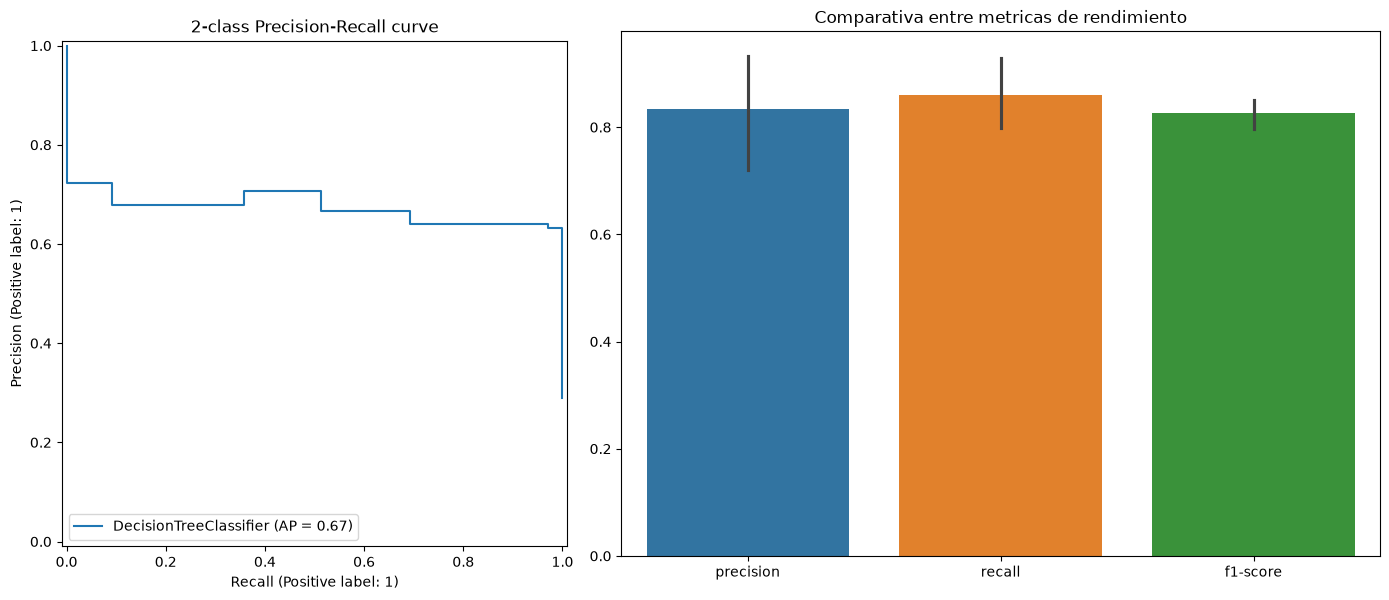

{'y_pred': array([1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1,
        0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1,
        0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0,
        1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0,
        1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0,
        1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0,
        0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0,
        1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0,
        0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
        1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1,
        0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
        1, 0, 0, 0, 0, 1, 0,

In [356]:
eval_model(is_classification=True, model=decision_tree_sin_reduccion, X=X_test, y=y_test)

##### Interpretabilidad 

In [357]:
nombres_variables = (
    pipeline_decision_tree_sin_reduccion
    .named_steps['preprocessor']
    .get_feature_names_out()
)

In [358]:
# Asociar las clases originales con sus etiquetas

mapa_clases = {
    0: "Usuario tiende a no suscribirse",
    1: "Usuario tiende a suscribirse"
}

# Obtener los nombres respetando el orden de las clases del modelo

nombre_clases = [mapa_clases[clase] for clase in pipeline_decision_tree_sin_reduccion.classes_]

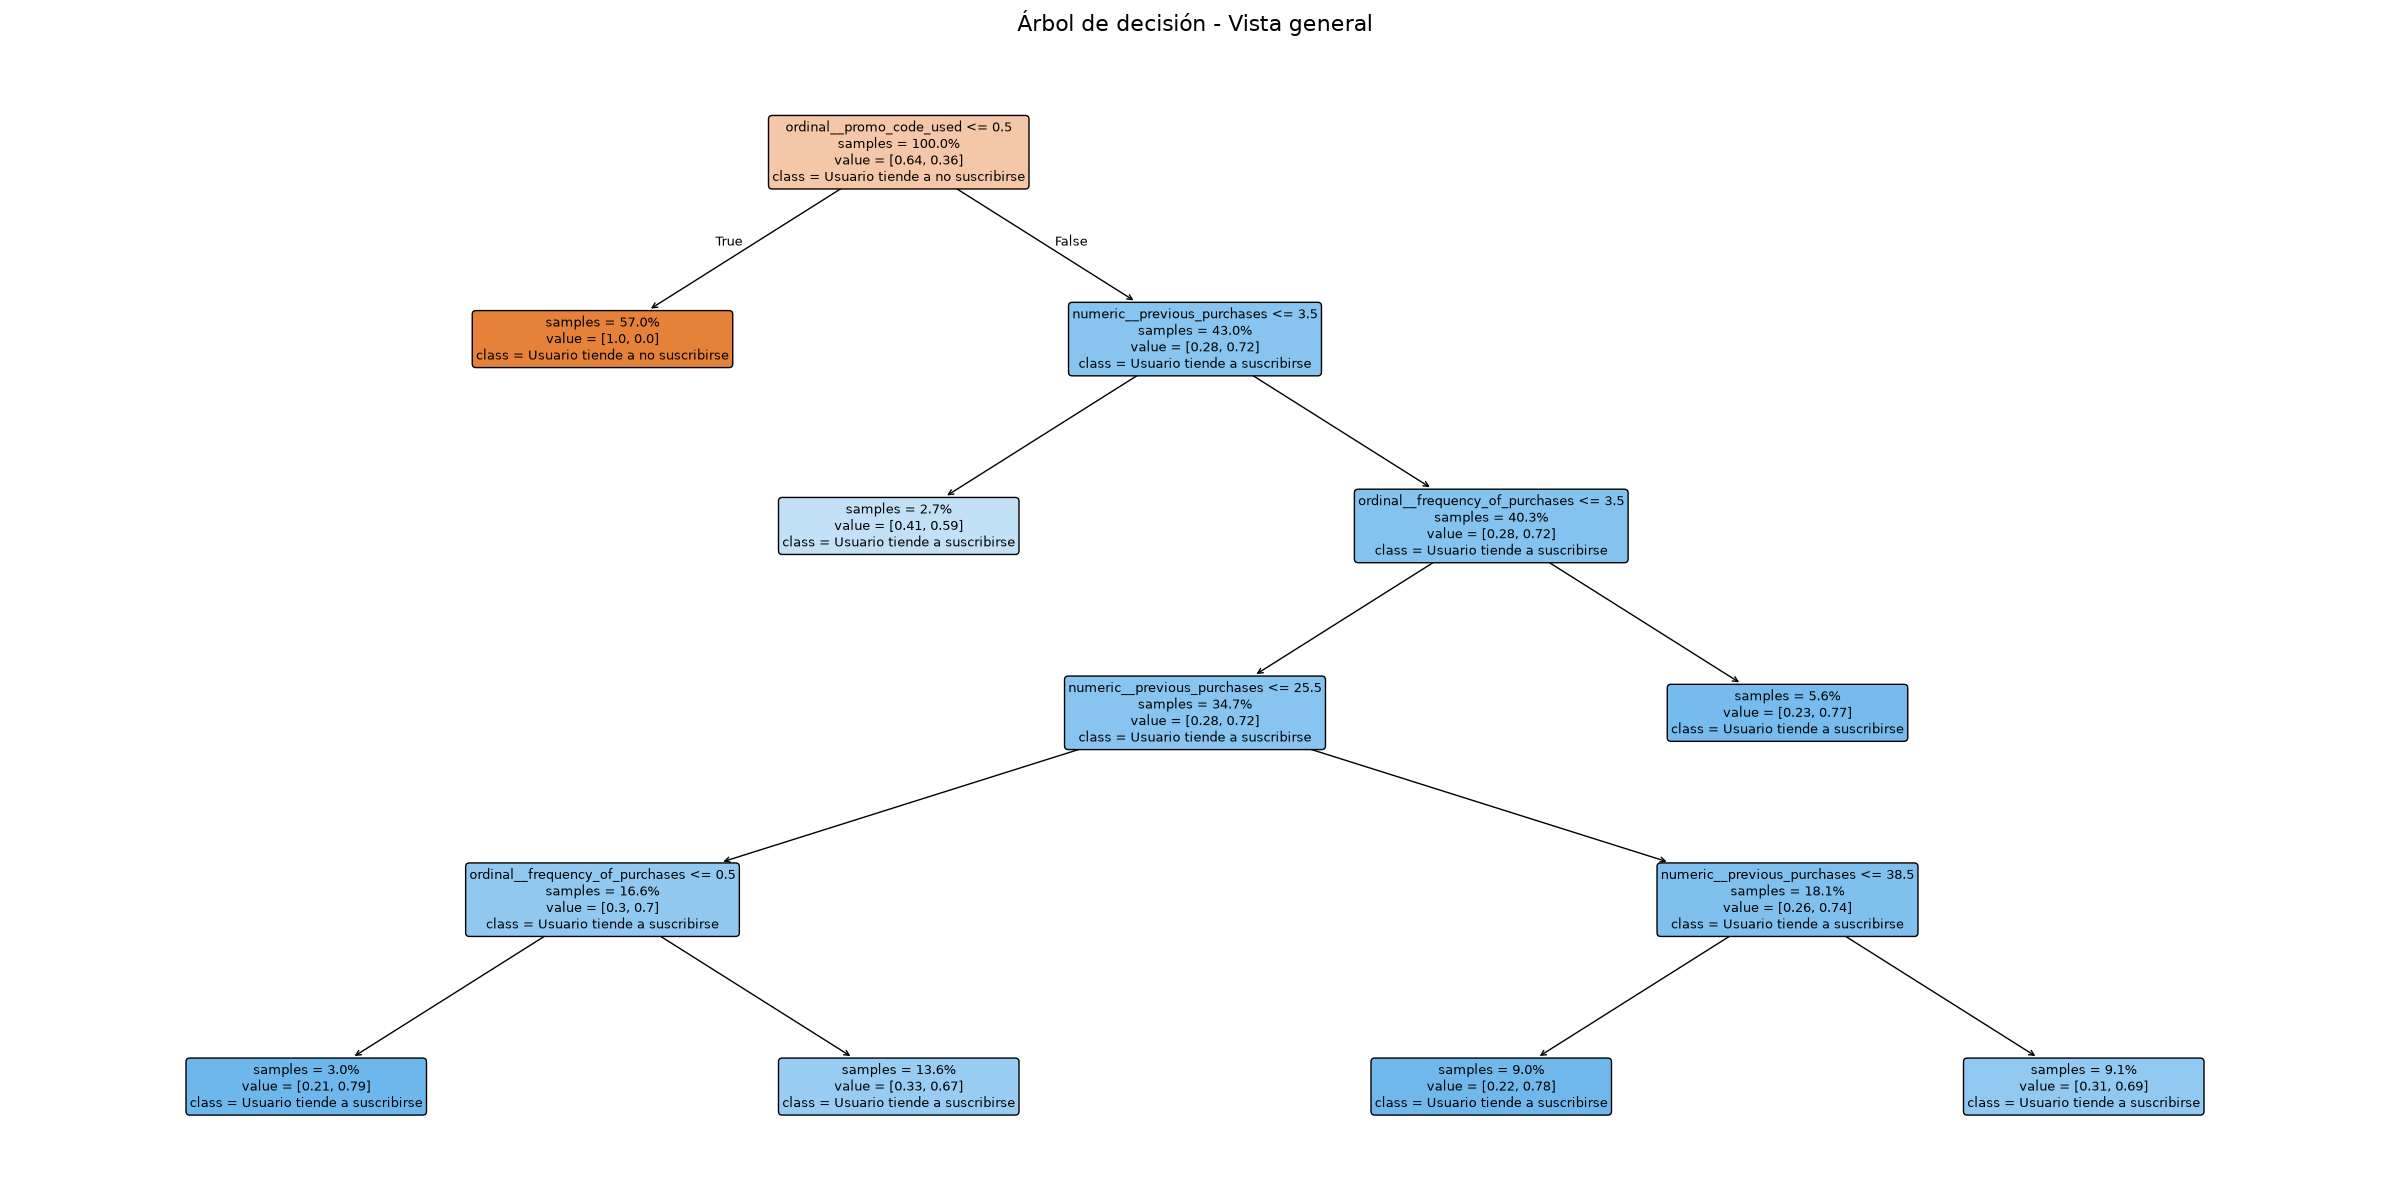

In [359]:
# Crear la figura
fig, ax = plt.subplots(figsize=(24, 12))

plot_tree(
    decision_tree_sin_reduccion,
    max_depth=15,  # Mostrar solo los primeros niveles
    filled=True,
    rounded=True,
    feature_names=nombres_variables,
    class_names=nombre_clases,
    fontsize=9,
    proportion=True,
    precision=2,
    impurity=False,
    ax=ax
)

ax.set_title(
    "Árbol de decisión - Vista general",
    fontsize=16,
    pad=20
)

plt.tight_layout()

plt.show()

In [360]:
pd.DataFrame({'Columnas preprocesadas':nombres_variables, 'Importancia':decision_tree_sin_reduccion.feature_importances_}).sort_values(by='Importancia', ascending=False).round(10)#['Columnas preprocesadas']

,Columnas preprocesadas,Importancia
3,ordinal__promo_code_used,0.988892
2,numeric__previous_purchases,0.007442
4,ordinal__frequency_of_purchases,0.003665
0,numeric__purchase_amount_usd,0.000000
1,numeric__review_rating,0.000000


#### Elasticnet

In [361]:
best_models[('ElasticNet', 'Sin reducción')]

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('all_columns', GeneralPreprocessor()),
                                 ('by_data_type_columns',
                                  ColumnTransformer(sparse_threshold=0,
                                                    transformers=[('numeric',
                                                                   'passthrough',
                                                                   ['purchase_amount_usd',
                                                                    'review_rating',
                                                                    'previous_purchases']),
                                                                  ('ordinal',
                                                                   Pipeline(steps=[('encoder',
                                                                                    OrdinalEncoder(categories=[['no',
                                                                                                                'yes'],
                                                                                                               ['annually',
                                                                                                                'quarterly',
                                                                                                                'monthly',
                                                                                                                'bi-weekly',
                                                                                                                'weekly']],
                                                                                                   handle_unknown='use_encoded_value',
                                                                                                   unknown_value=-1))]),
                                                                   ['promo_code_used',
                                                                    'frequency_of_purchases'])]))])),
                ('reduction', 'passthrough'),
                ('model',
                 SGDClassifier(l1_ratio=0.2, loss='log_loss', max_iter=3000,
                               penalty='elasticnet', random_state=42))])

In [362]:
pipeline_elasticnet_sin_reduccion = best_models[('ElasticNet', 'Sin reducción')]

In [363]:
elasticnet_sin_reduccion = pipeline_elasticnet_sin_reduccion.named_steps['model']

##### Evaluación

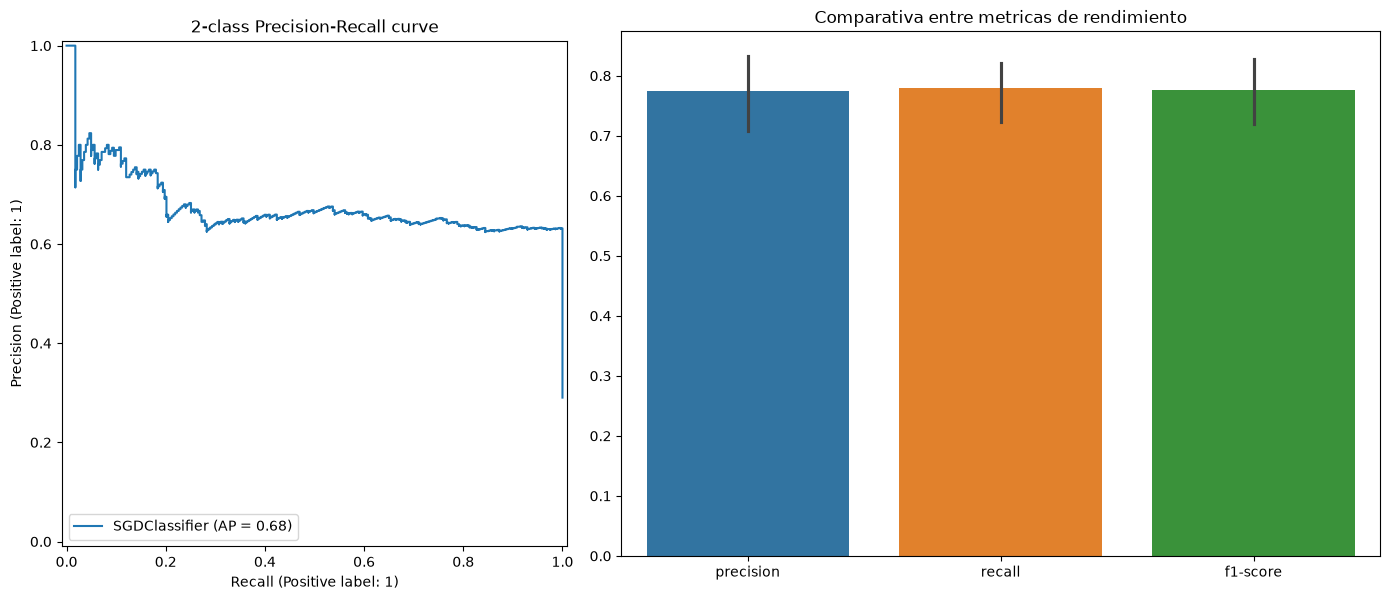

{'y_pred': array([0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1,
        0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1,
        0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0,
        0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0,
        0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0,
        0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0,
        1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
        1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0,
        0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
        1, 0, 0, 0, 0, 1, 0,

In [364]:
eval_model(model=elasticnet_sin_reduccion, is_classification=True, X=X_test, y=y_test)

##### Interpretavilidad

In [365]:
pd.DataFrame({'Columns':preprocessor.get_feature_names_out(), 'Coeficientes':elasticnet_sin_reduccion.coef_[0]}).sort_values(by=['Coeficientes'], ascending=False)

,Columns,Coeficientes
3,ordinal__promo_code_used,218.687082
1,numeric__review_rating,6.546954
4,ordinal__frequency_of_purchases,0.685702
2,numeric__previous_purchases,0.376215
0,numeric__purchase_amount_usd,0.000000


##### Hipotesis diagnosticas sobre variables asociadas a la suscripción

A partir de los resultados obtenidos en la primera iteración del modelado, se identificaron cinco variables relevantes para la segmentación de los clientes según su propensión a suscribirse: el uso de códigos promocionales, el monto de la compra, la valoración del producto (review_rating) y el número de compras previas, y el monto de compra hecho por el usuario (siendo esta ultima una relación aparentemente no lineal o bajo ciertos segmentos muy concretos, dado que el arbol le asigna una de las importancias mas altas, mientras que ElasticNet un coeficiente nulo).

Durante esta breve instancia de interpretabilidad diagnostica, el objetivo contrastar estas hipótesis mediante el análisis de las tasas de suscripción por grupos, la visualización de sus distribuciones y la comparación de las diferencias observadas. De este modo, se buscará determinar la dirección y magnitud de las asociaciones entre las variables seleccionadas y la suscripción, sin asumir de antemano que estas relaciones son crecientes ni que implican causalidad.




H1. Uso de códigos promocionales: la tasa de suscripción difiere entre los clientes que utilizan códigos promocionales y aquellos que no los utilizan.




Tabla de contingencia bivariada en mapa de calor

In [400]:
tabla_contingencia_promo_c_target = pd.crosstab(df_processed['subscription_status'], df_processed['promo_code_used'], normalize=True)
tabla_contingencia_promo_c_target

promo_code_used,no,yes
subscription_status,,
no,0.57,0.16
yes,0.00,0.27


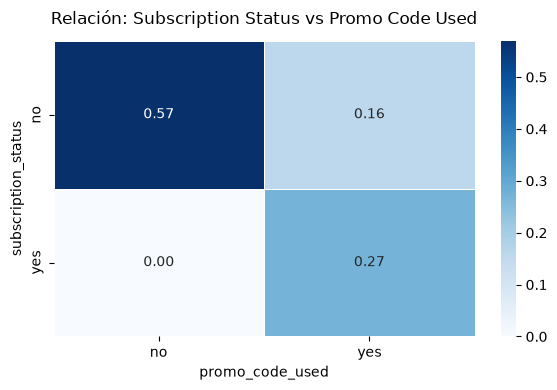

In [401]:
# Definir el tamaño de la figura para que no se vea apretada
plt.figure(figsize=(6, 4))

sns.heatmap(
    data=tabla_contingencia_promo_c_target,
    annot=True,  # Muestra los valores numéricos en las celdas
    fmt='.2f',  # Formato de decimales (usa 'd' si tu tabla tiene conteos enteros)
    cmap='Blues',  # Paleta secuencial, ideal para proporciones/conteos
    linewidths=0.5,  # Líneas de separación entre celdas
    linecolor='white',  # Color de las líneas divisorias
    cbar=True,  # Mantiene la barra de escala lateral
)

# Agregar títulos y etiquetas claras
plt.title(
    'Relación: Subscription Status vs Promo Code Used', fontsize=12, pad=12
)
plt.xlabel('promo_code_used', fontsize=10)
plt.ylabel('subscription_status', fontsize=10)

plt.tight_layout()
plt.show()

Gráfico de barras que muestre el porcentaje de clientes suscritos en cada grupo, y intervalos de confianza del 95 % para mostrar la incertidumbre de las tasas estimadas.

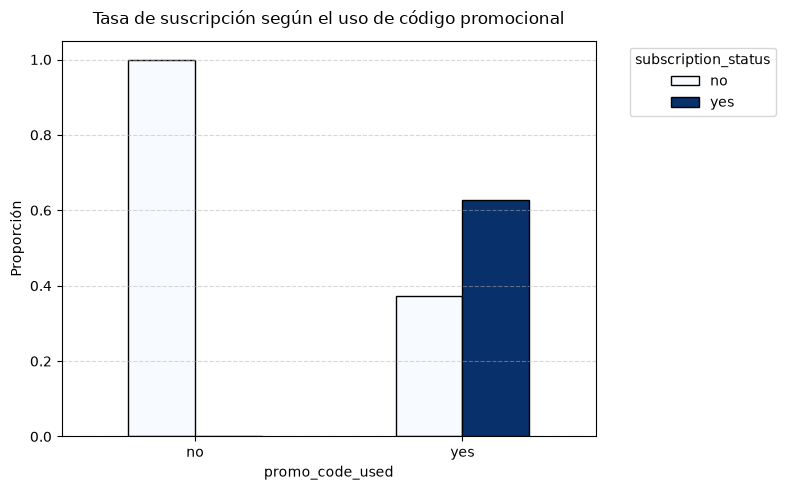

In [402]:
# Generar el gráfico de barras directamente desde la tabla de contingencia
tasa_por_promo.plot(
    kind='bar',
    figsize=(8, 5),
    colormap='Blues',  # Paleta de colores
    edgecolor='black',  # Borde negro sutil para las barras
)

# Personalizar el gráfico
plt.title(
    'Tasa de suscripción según el uso de código promocional',
    fontsize=12,
    pad=12,
)
plt.xlabel('promo_code_used', fontsize=10)
plt.ylabel('Proporción', fontsize=10)
plt.xticks(rotation=0)  # Mantiene las etiquetas horizontales
plt.legend(title='subscription_status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Prueba de independencia chi-cuadrado bivariada

In [ ]:
chi2_stat, p_value, dof, expected = chi2_contingency(pd.crosstab(df_processed['subscription_status'], df_processed['promo_code_used']))
p_value

np.float64(0.0)

H2. Numero de compras previas mayores, tienden a estar relacionadas con mayor probabilidad de subscripción

Gráfico de caja con numero de compras previas, separado por subscripción vs no subscripción

In [ ]:
df_processed.columns

Index(['age', 'gender', 'item_purchased', 'category_item',
       'purchase_amount_usd', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'promo_code_used', 'previous_purchases', 'payment_method',
       'frequency_of_purchases'],
      dtype='str')

<Axes: ylabel='previous_purchases'>

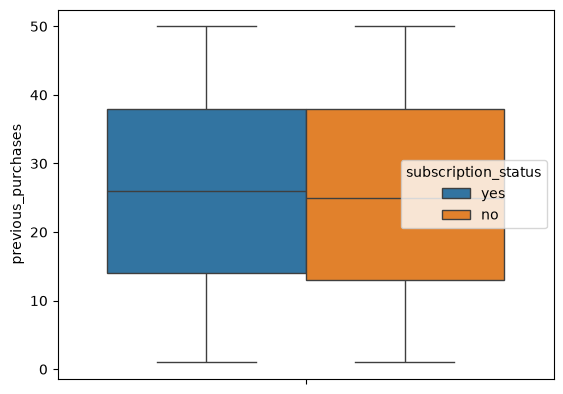

In [ ]:
sns.boxplot(df_processed, y='previous_purchases', hue='subscription_status')

Test de Anova

In [ ]:
import scipy.stats as stats

In [ ]:
df_processed.groupby(by='subscription_status')['previous_purchases'].mean()

subscription_status
no     25.080436
yes    26.084520
Name: previous_purchases, dtype: float64

In [ ]:
# Separar la variable numérica según las categorías de suscripción
compras_no = df_processed[df_processed['subscription_status'] == 'no'][
    'previous_purchases'
]
compras_yes = df_processed[df_processed['subscription_status'] == 'yes'][
    'previous_purchases'
]

# Ejecutar la prueba ANOVA
f_stat, p_value = stats.f_oneway(compras_no, compras_yes)

print(f"Estadístico F: {f_stat:.4f}")
print(f"P-value: {p_value}")

Estadístico F: 3.7156
P-value: 0.05397809617764757


Test de Mann-Whitney U

In [ ]:
df_processed.groupby('subscription_status')['previous_purchases'].median()

subscription_status
no     25.0
yes    26.0
Name: previous_purchases, dtype: float64

In [ ]:
stat, p_val = stats.mannwhitneyu(compras_no, compras_yes)
print(f"P-value Mann-Whitney: {p_val}")

P-value Mann-Whitney: 0.05252329112817023


H3. Montos de compras superiores, tienden a mayor subscripción

> En esta hipotesis en particular, se deberia analizar especificamente el segmento que identifico el arbol, ya que es una partición que tiene sentido para este, y no de manera lineal directa con la target. Recordemos que ElasticNet bajo el coeficiente asignado a 0, y que en configuraciones actuales y menos profunda del arbol, la importancia tambien cayo a 0.

In [ ]:
# 1. Filtramos el segmento de interés basado en lo que muestra el árbol
segmento_especifico_h3 = df_processed[
    df_processed['promo_code_used'] == 'yes'
]

Gráfico de caja con numero de compras previas, separado por subscripción vs no subscripción

<Axes: ylabel='purchase_amount_usd'>

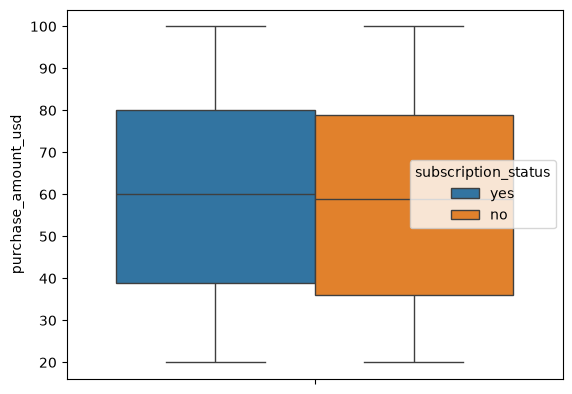

In [ ]:
sns.boxplot(segmento_especifico_h3, y='purchase_amount_usd', hue='subscription_status')

Grafico de barras de la tasa de suscripción por intervalos de monto (bajo, medio-bajo, medio-alto, y alto) utilizando cuartiles de la distribución.

In [ ]:
segmento_especifico_h3['discrete_purchase_usd'] = pd.qcut(segmento_especifico_h3['purchase_amount_usd'], q=4, labels=['bajo', 'medio-bajo', 'medio-alto', 'alto'])

<Axes: xlabel='discrete_purchase_usd'>

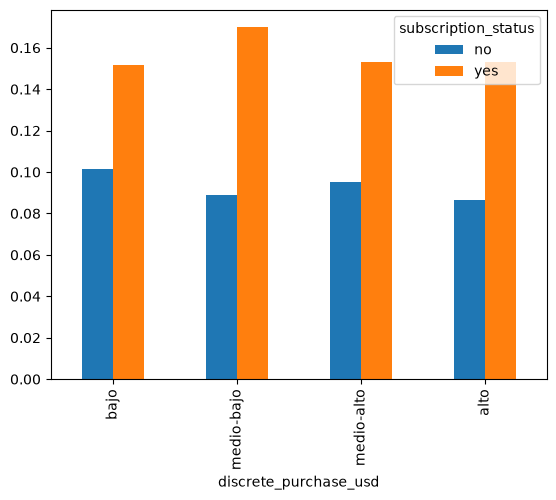

In [ ]:
pd.crosstab(segmento_especifico_h3['discrete_purchase_usd'], segmento_especifico_h3['subscription_status'], normalize=True).plot(kind='bar')

Test de Anova

In [ ]:
# Separar la variable numérica según las categorías de suscripción
compras_no = segmento_especifico_h3[segmento_especifico_h3['subscription_status'] == 'no'][
    'purchase_amount_usd'
]
compras_yes = segmento_especifico_h3[segmento_especifico_h3['subscription_status'] == 'yes'][
    'purchase_amount_usd'
]

In [ ]:
# Ejecutar la prueba ANOVA
f_stat, p_value = stats.f_oneway(compras_no, compras_yes)

print(f"Estadístico F: {f_stat:.4f}")
print(f"P-value: {p_value}")

Estadístico F: 0.2299
P-value: 0.6316602552274833


Test de Mann-Whitney U

In [ ]:
stat, p_val = stats.mannwhitneyu(compras_no, compras_yes)
print(f"P-value Mann-Whitney: {p_val}")

P-value Mann-Whitney: 0.6131356469389277


H4. Ratings mas altos, tienden a mayor tasa de subscripción

Gráfico de caja con numero de ratings, separado por subscripción vs no subscripción

<Axes: ylabel='review_rating'>

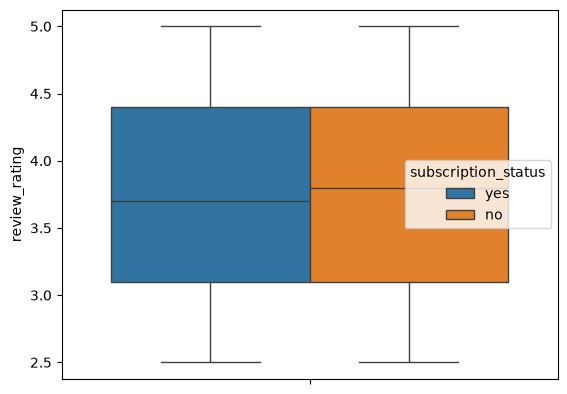

In [405]:
sns.boxplot(df_processed, y='review_rating', hue='subscription_status')

Grafico de barras de la tasa de suscripción por intervalos de rating (bajo, medio-bajo, medio-alto, y alto) utilizando cuartiles de la distribución.

In [414]:
df_processed['discrete_review_rating'] = pd.qcut(df_processed['review_rating'],q=4, labels=['bajo', 'bajo-medio', 'medio-alto', 'alto'])
df_processed['discrete_review_rating']

0             bajo
1             bajo
2             bajo
3       bajo-medio
4             bajo
           ...    
3895    medio-alto
3896          alto
3897          bajo
3898    medio-alto
3899          bajo
Name: discrete_review_rating, Length: 3900, dtype: category
Categories (4, str): ['bajo' < 'bajo-medio' < 'medio-alto' < 'alto']

<Axes: xlabel='discrete_review_rating'>

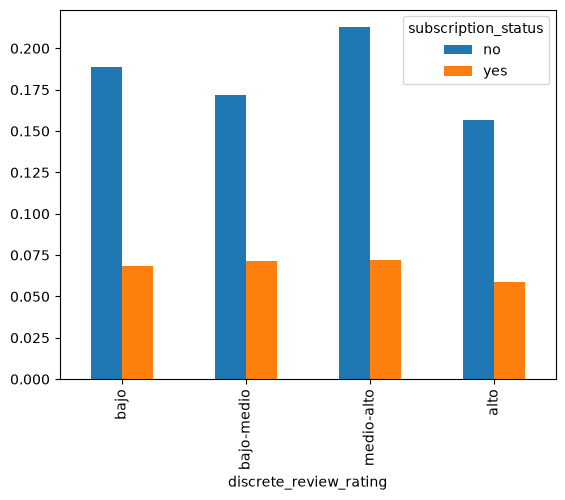

In [417]:
pd.crosstab(df_processed['discrete_review_rating'], df_processed['subscription_status'], normalize=True).plot(
    kind='bar'
)

<Axes: xlabel='subscription_status', ylabel='discrete_review_rating'>

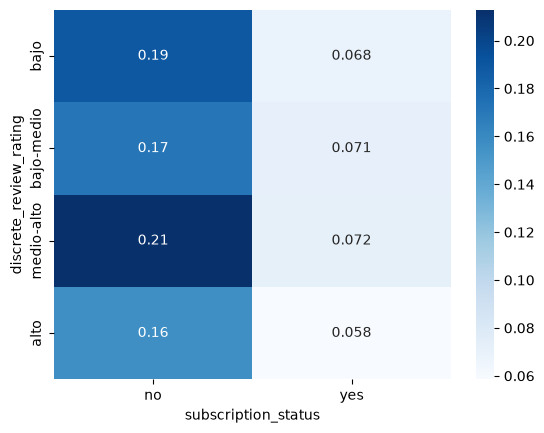

In [420]:
sns.heatmap(pd.crosstab(df_processed['discrete_review_rating'], df_processed['subscription_status'], normalize=True), annot=True, cmap='Blues')

Test de Anova

In [ ]:
# Separar la variable numérica según las categorías de suscripción
compras_no = df_processed[df_processed['subscription_status'] == 'no'][
    'review_rating'
]
compras_yes = df_processed[df_processed['subscription_status'] == 'yes'][
    'review_rating'
]

In [412]:
# Ejecutar la prueba ANOVA
f_stat, p_value = stats.f_oneway(compras_no, compras_yes)

print(f"P-value: {p_value}")

P-value: 0.690953510741934


In [410]:
df_processed.groupby(by=['subscription_status'])['review_rating'].mean()

subscription_status
no     3.752722
yes    3.742450
Name: review_rating, dtype: float64

Test de Mann-Whitney U

In [408]:
stat, p_val = stats.mannwhitneyu(compras_no, compras_yes)
print(f"P-value Mann-Whitney: {p_val}")

P-value Mann-Whitney: 0.7011474610176017


In [411]:
df_processed.groupby(by=['subscription_status'])['review_rating'].median()

subscription_status
no     3.8
yes    3.7
Name: review_rating, dtype: float64

H5. Usuarios con frecuencia de compras mas consecutivos en el tiempo, tienden a subscribirse mas

In [423]:
tabla_contingencia_review_rating = pd.crosstab(df_processed['frequency_of_purchases'], df_processed['subscription_status'], normalize=True)
tabla_contingencia_review_rating

subscription_status,no,yes
frequency_of_purchases,,
annually,0.105641,0.041026
bi-weekly,0.204103,0.075128
monthly,0.103590,0.038205
quarterly,0.218718,0.075385
weekly,0.097949,0.040256


Gráfico de barras que muestre el porcentaje de clientes suscritos en cada grupo, y intervalos de confianza del 95 % para mostrar la incertidumbre de las tasas estimadas.

<Axes: xlabel='frequency_of_purchases'>

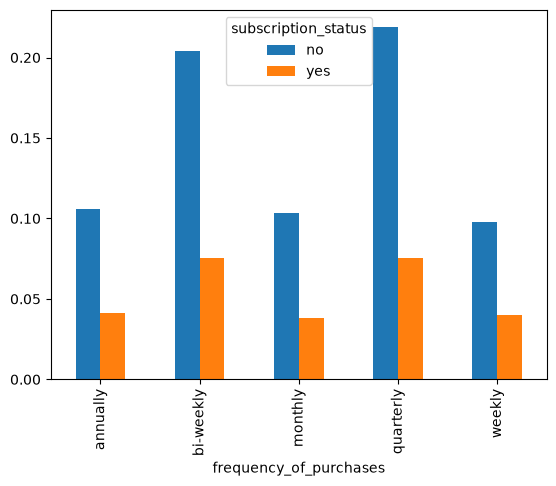

In [ ]:
tabla_contingencia_review_rating.plot(kind='bar')

Tabla de contingencia bivariada en mapa de calor

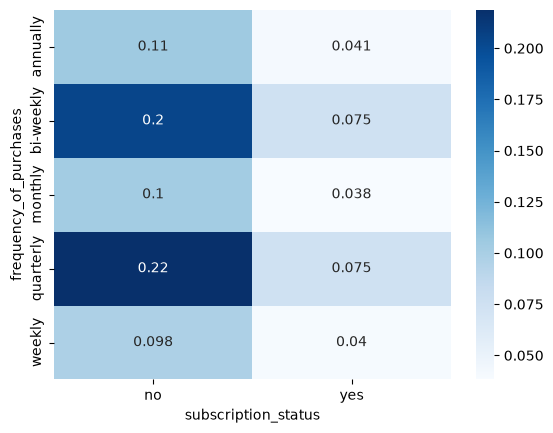

In [431]:
sns.heatmap(tabla_contingencia_review_rating, cmap='Blues', annot=True)
plt.show()

Prueba de independencia chi-cuadrado bivariada

In [433]:
chi2_stat, p_value, dof, expected = chi2_contingency(pd.crosstab(df_processed['frequency_of_purchases'], df_processed['subscription_status']))
p_value

np.float64(0.625527568929042)

### Guardado del mejor modelo

In [ ]:
# Guardar el modelo entrenado en un archivo .pkl
path_best_ml_model = '../models/subscription_status_decision_tree_base_model.pkl'
joblib.dump(decision_tree_sin_reduccion, path_best_ml_model)

['../models/subscription_status_decision_tree_base_model.pkl']

---